In [4]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy
!pip install qiskit-machine-learning
!pip install pennylane scikit-learn matplotlib
!pip install qiskit-algorithms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 3.6 MB/s eta 0:00:00


STEP 2. History
COBYLA Evaluation : 28
SPSA Evaluation   : 251


STEP 3. COBYLA Loss Curve


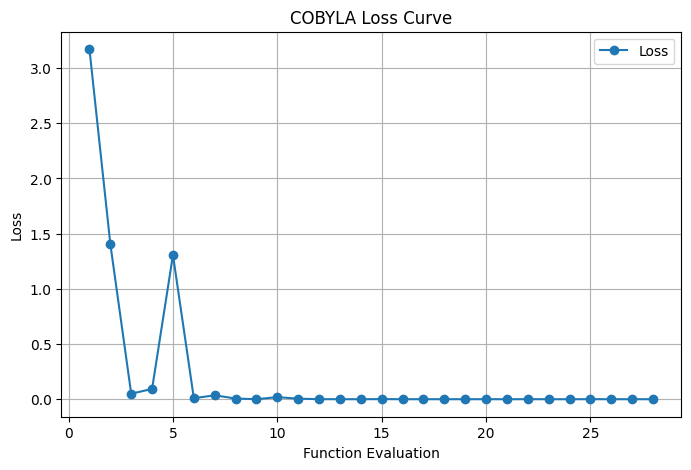

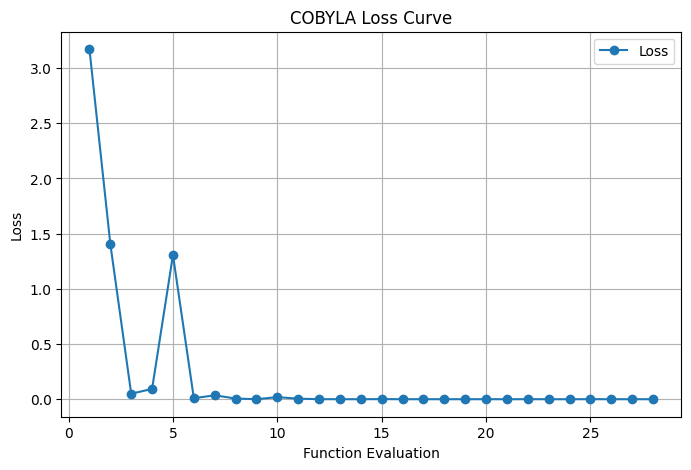



STEP 4. SPSA Loss Curve


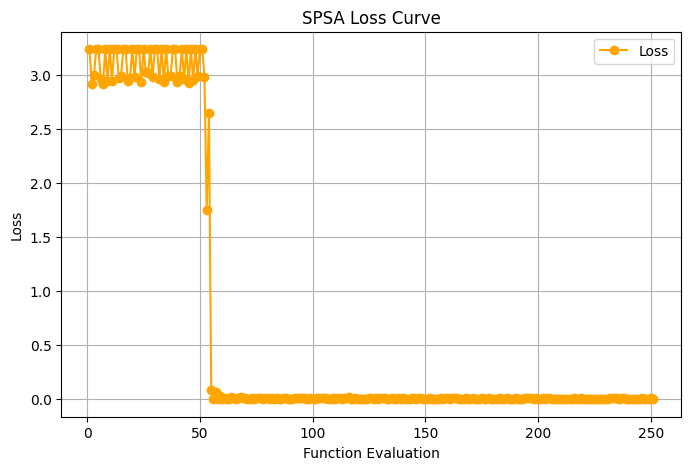

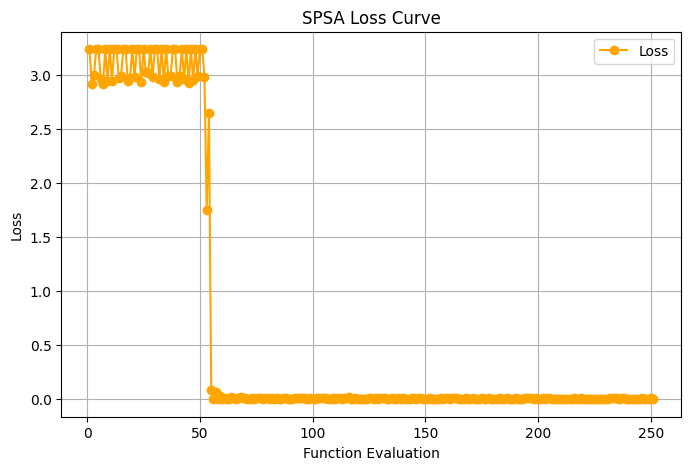



STEP 5. Best Loss Comparison


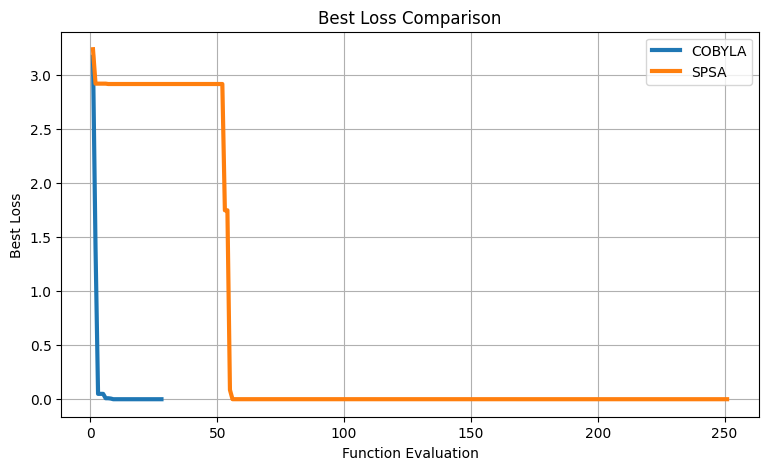

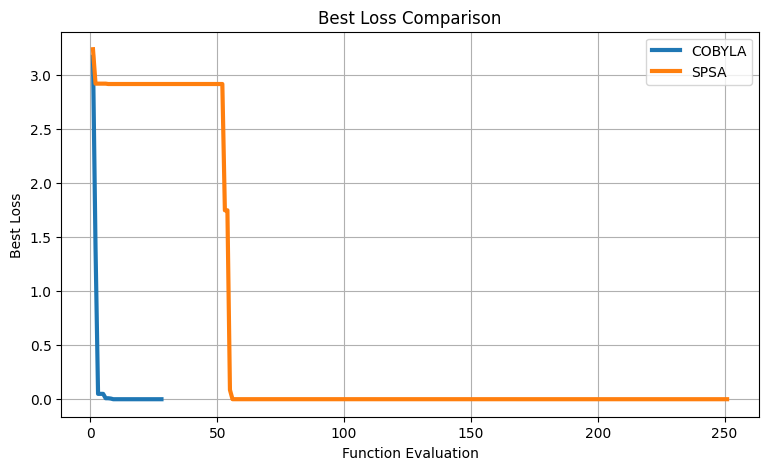



STEP 6. Parameter Curve


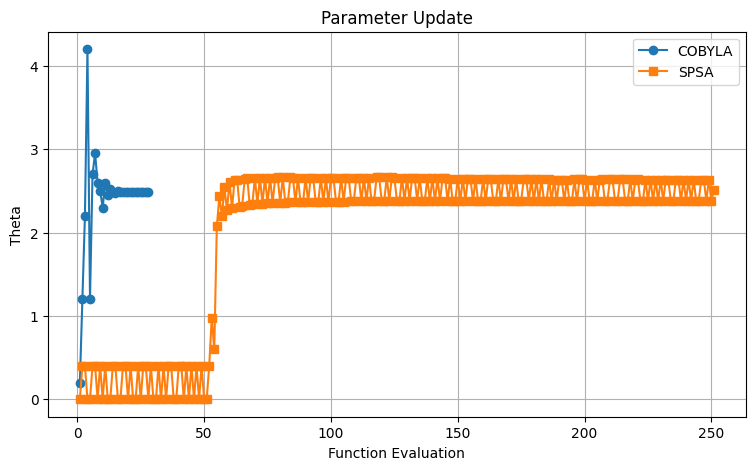

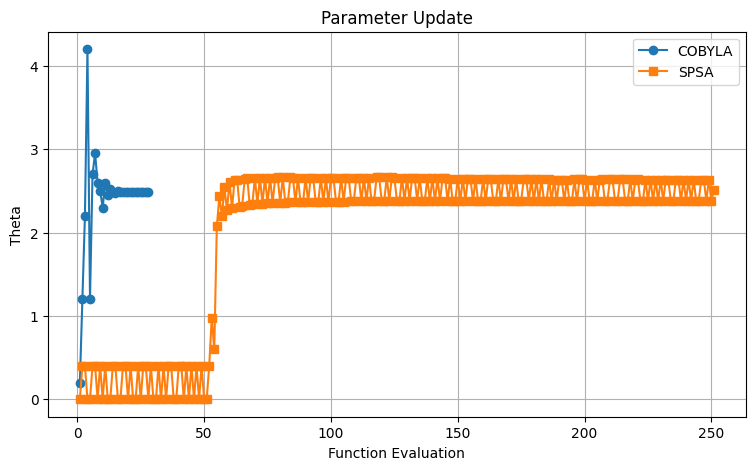



STEP 7. Prediction Curve


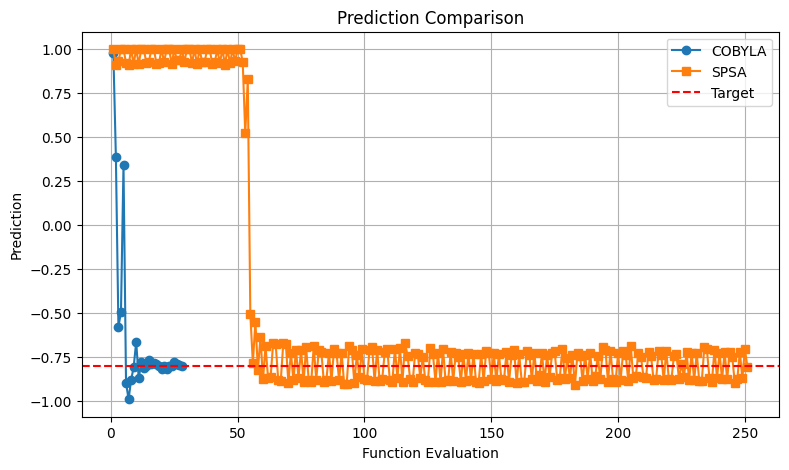

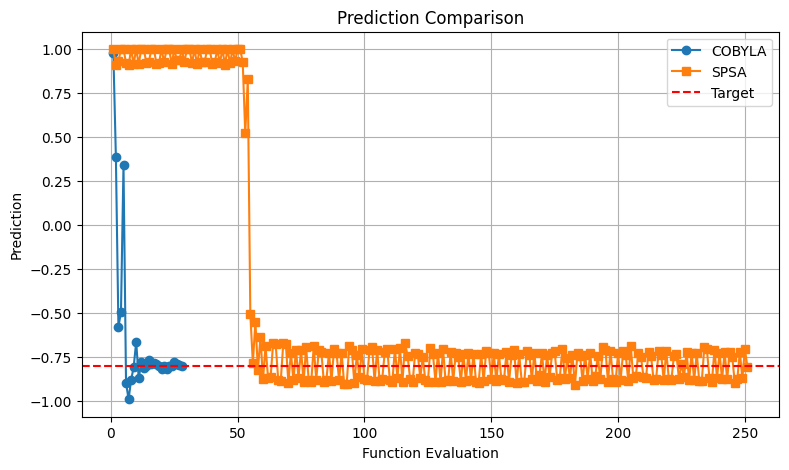



STEP 8. Loss Landscape


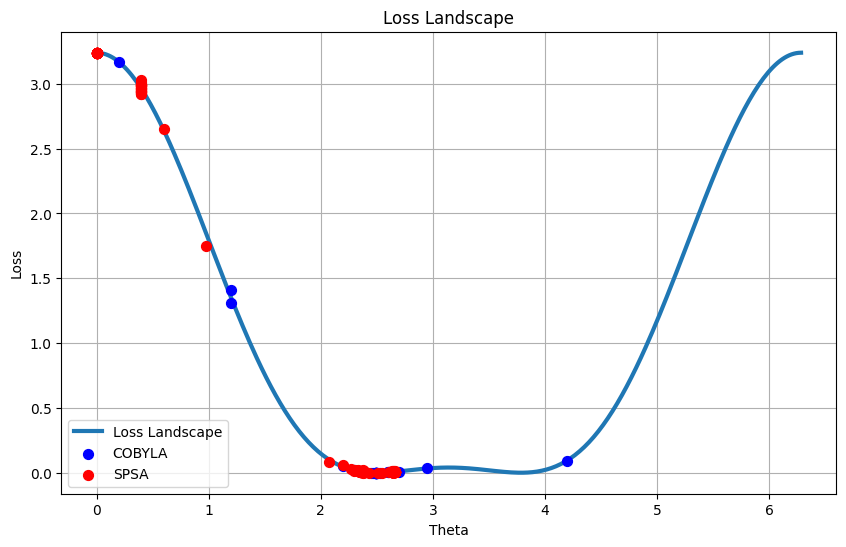

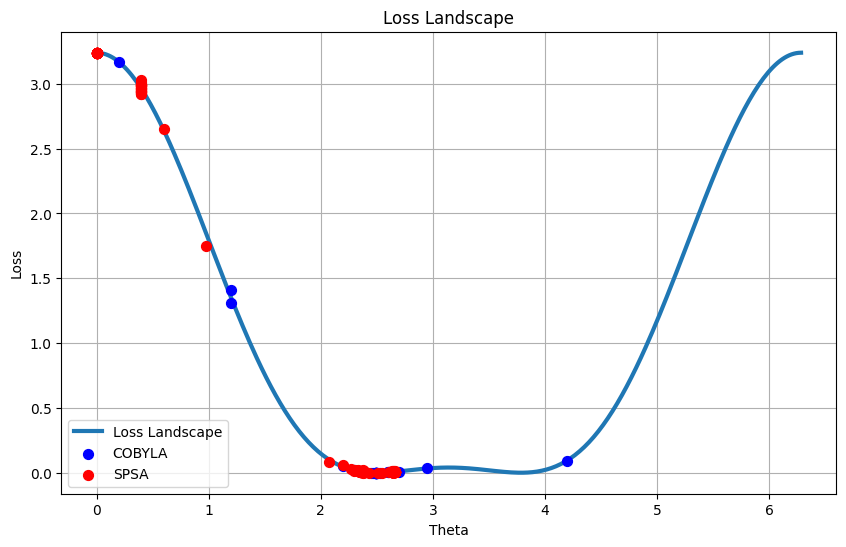



STEP 9. Evaluation Comparison


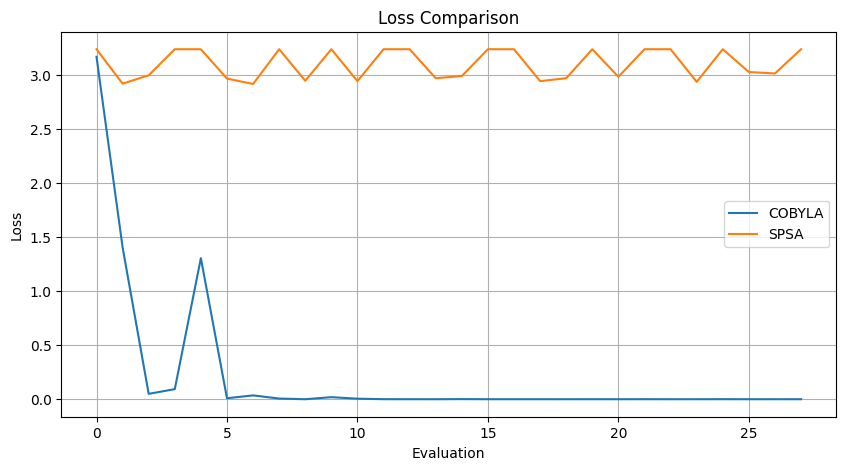

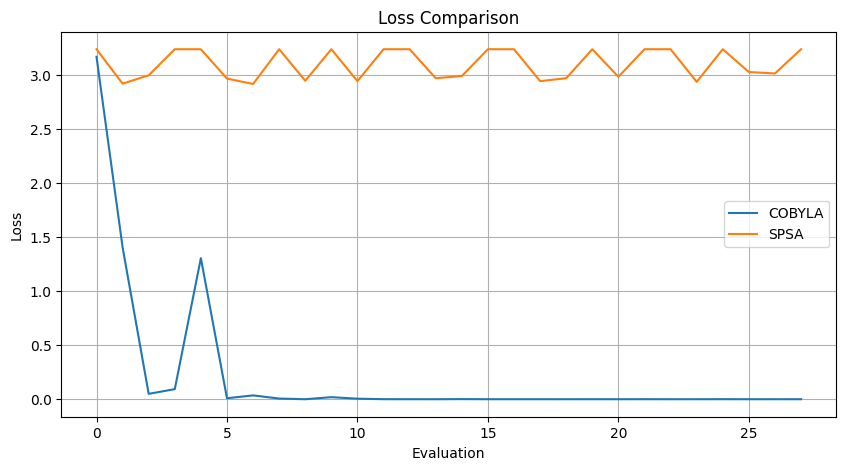



STEP 10. Final Result
--------------------------------------------------------------------------------
COBYLA
Parameter  : 2.48899
Prediction : -0.80078
Loss       : 0.00000061
--------------------------------------------------------------------------------
SPSA
Parameter  : 2.50939
Prediction : -0.80664
Loss       : 0.00004410


STEP 11. Summary Table
Item                     COBYLA         SPSA           
------------------------------------------------------------
Final Parameter          2.48899        2.50939        
Prediction               -0.80078       -0.80664       
Best Loss                0.00000061     0.00004410     
Evaluation               28             251            
Visualization Complete


In [7]:
%matplotlib inline

# ============================================================
# STEP 1. Library Import
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# STEP 2. History 확인
# ============================================================

print("=" * 80)
print("STEP 2. History")
print("=" * 80)

print("COBYLA Evaluation :", len(cobyla_history["evaluation"]))
print("SPSA Evaluation   :", len(spsa_history["evaluation"]))

# ============================================================
# STEP 3. COBYLA Loss Curve
# ============================================================

print("\n")
print("=" * 80)
print("STEP 3. COBYLA Loss Curve")
print("=" * 80)

fig1 = plt.figure(figsize=(8, 5))
plt.plot(
    cobyla_history["evaluation"],
    cobyla_history["loss"],
    marker="o",
    label="Loss"
)
plt.xlabel("Function Evaluation")
plt.ylabel("Loss")
plt.title("COBYLA Loss Curve")
plt.grid(True)
plt.legend()
display(fig1)
plt.show()

# ============================================================
# STEP 4. SPSA Loss Curve
# ============================================================

print("\n")
print("=" * 80)
print("STEP 4. SPSA Loss Curve")
print("=" * 80)

fig2 = plt.figure(figsize=(8, 5))
plt.plot(
    spsa_history["evaluation"],
    spsa_history["loss"],
    marker="o",
    color="orange",
    label="Loss"
)
plt.xlabel("Function Evaluation")
plt.ylabel("Loss")
plt.title("SPSA Loss Curve")
plt.grid(True)
plt.legend()
display(fig2)
plt.show()

# ============================================================
# STEP 5. Best Loss 비교
# ============================================================

print("\n")
print("=" * 80)
print("STEP 5. Best Loss Comparison")
print("=" * 80)

fig3 = plt.figure(figsize=(9, 5))
plt.plot(
    cobyla_history["evaluation"],
    cobyla_history["best_loss"],
    linewidth=3,
    label="COBYLA"
)
plt.plot(
    spsa_history["evaluation"],
    spsa_history["best_loss"],
    linewidth=3,
    label="SPSA"
)
plt.xlabel("Function Evaluation")
plt.ylabel("Best Loss")
plt.title("Best Loss Comparison")
plt.grid(True)
plt.legend()
display(fig3)
plt.show()

# ============================================================
# STEP 6. Parameter Curve
# ============================================================

print("\n")
print("=" * 80)
print("STEP 6. Parameter Curve")
print("=" * 80)

fig4 = plt.figure(figsize=(9, 5))
plt.plot(
    cobyla_history["evaluation"],
    cobyla_history["parameter"],
    marker="o",
    label="COBYLA"
)
plt.plot(
    spsa_history["evaluation"],
    spsa_history["parameter"],
    marker="s",
    label="SPSA"
)
plt.xlabel("Function Evaluation")
plt.ylabel("Theta")
plt.title("Parameter Update")
plt.grid(True)
plt.legend()
display(fig4)
plt.show()

# ============================================================
# STEP 7. Prediction Curve
# ============================================================

print("\n")
print("=" * 80)
print("STEP 7. Prediction Curve")
print("=" * 80)

fig5 = plt.figure(figsize=(9, 5))
plt.plot(
    cobyla_history["evaluation"],
    cobyla_history["prediction"],
    marker="o",
    label="COBYLA"
)
plt.plot(
    spsa_history["evaluation"],
    spsa_history["prediction"],
    marker="s",
    label="SPSA"
)
plt.axhline(
    y=target,
    color="red",
    linestyle="--",
    label="Target"
)
plt.xlabel("Function Evaluation")
plt.ylabel("Prediction")
plt.title("Prediction Comparison")
plt.grid(True)
plt.legend()
display(fig5)
plt.show()

# ============================================================
# STEP 8. Loss Landscape
# ============================================================

print("\n")
print("=" * 80)
print("STEP 8. Loss Landscape")
print("=" * 80)

theta_space = np.linspace(
    0,
    2 * np.pi,
    300
)

landscape = (
    np.cos(theta_space) - target
) ** 2

fig6 = plt.figure(figsize=(10, 6))
plt.plot(
    theta_space,
    landscape,
    linewidth=3,
    label="Loss Landscape"
)
plt.scatter(
    cobyla_history["parameter"],
    cobyla_history["loss"],
    color="blue",
    s=50,
    zorder=5,
    label="COBYLA"
)
plt.scatter(
    spsa_history["parameter"],
    spsa_history["loss"],
    color="red",
    s=50,
    zorder=6,
    label="SPSA"
)
plt.xlabel("Theta")
plt.ylabel("Loss")
plt.title("Loss Landscape")
plt.grid(True)
plt.legend()
display(fig6)
plt.show()

# ============================================================
# STEP 9. Evaluation별 Loss 비교
# ============================================================

print("\n")
print("=" * 80)
print("STEP 9. Evaluation Comparison")
print("=" * 80)

max_eval = min(
    len(cobyla_history["loss"]),
    len(spsa_history["loss"])
)

fig7 = plt.figure(figsize=(10, 5))
plt.plot(
    range(max_eval),
    cobyla_history["loss"][:max_eval],
    label="COBYLA"
)
plt.plot(
    range(max_eval),
    spsa_history["loss"][:max_eval],
    label="SPSA"
)
plt.xlabel("Evaluation")
plt.ylabel("Loss")
plt.title("Loss Comparison")
plt.grid(True)
plt.legend()
display(fig7)
plt.show()

# ============================================================
# STEP 10. 최종 결과 비교
# ============================================================

print("\n")
print("=" * 80)
print("STEP 10. Final Result")
print("=" * 80)

cobyla_final_parameter = cobyla_history["parameter"][-1]
cobyla_final_prediction = cobyla_history["prediction"][-1]
cobyla_final_loss = cobyla_history["best_loss"][-1]

spsa_final_parameter = spsa_history["parameter"][-1]
spsa_final_prediction = spsa_history["prediction"][-1]
spsa_final_loss = spsa_history["best_loss"][-1]

print("-" * 80)
print("COBYLA")
print(f"Parameter  : {cobyla_final_parameter:.5f}")
print(f"Prediction : {cobyla_final_prediction:.5f}")
print(f"Loss       : {cobyla_final_loss:.8f}")

print("-" * 80)
print("SPSA")
print(f"Parameter  : {spsa_final_parameter:.5f}")
print(f"Prediction : {spsa_final_prediction:.5f}")
print(f"Loss       : {spsa_final_loss:.8f}")

# ============================================================
# STEP 11. 결과 비교표 출력
# ============================================================

print("\n")
print("=" * 80)
print("STEP 11. Summary Table")
print("=" * 80)

print("{:<25}{:<15}{:<15}".format(
    "Item",
    "COBYLA",
    "SPSA"
))

print("-" * 60)

print("{:<25}{:<15.5f}{:<15.5f}".format(
    "Final Parameter",
    cobyla_final_parameter,
    spsa_final_parameter
))

print("{:<25}{:<15.5f}{:<15.5f}".format(
    "Prediction",
    cobyla_final_prediction,
    spsa_final_prediction
))

print("{:<25}{:<15.8f}{:<15.8f}".format(
    "Best Loss",
    cobyla_final_loss,
    spsa_final_loss
))

print("{:<25}{:<15}{:<15}".format(
    "Evaluation",
    len(cobyla_history["evaluation"]),
    len(spsa_history["evaluation"])
))

print("=" * 80)
print("Visualization Complete")
print("=" * 80)